<center><h1>Xie_Chong_HW3</h1></center>
<br>
<br>

Name: Chong Xie
<br>
Github Username: cxieusc
<br>
USC ID: 6800668300

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
import itertools
import statsmodels.api as sm
import os

### (b) Test and Train Data

In [4]:
data_dir = "../data/AReM"

columns = [
    "time",
    "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13",
    "avg_rss23", "var_rss23"
]

data = {}


for activity in os.listdir(data_dir):
    activity_dir = os.path.join(data_dir, activity)

    if not os.path.isdir(activity_dir):
        continue

    for filename in os.listdir(activity_dir):
        if not filename.startswith("dataset") or not filename.endswith(".csv"):
            continue

        file_path = os.path.join(activity_dir, filename)
        dataset_name = filename.removesuffix(".csv")

        df = pd.read_csv(
            file_path,
            comment="#",
            header=None,
            names=columns,
            sep=r"[,\s]+",
            engine="python",
            usecols=range(7)
        )

        data[(activity, dataset_name)] = df


In [5]:
data[("walking", "dataset1")].head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,35.00,3.67,16.50,3.77,14.00,1.63
1,250,28.50,3.35,17.50,3.77,12.25,3.90
2,500,35.50,2.87,15.75,2.86,17.75,5.07
3,750,29.75,12.19,16.25,2.17,20.75,2.59
4,1000,27.00,2.12,16.75,0.83,24.75,1.64


In [10]:
train_data = {}
test_data = {}

for (activity, dataset_name), df in data.items():
    dataset_id = int(dataset_name.replace("dataset", ""))

    if activity in ["bending1", "bending2"]:
        is_test = dataset_id <= 2
    else:
        is_test = dataset_id <= 3

    if is_test:
        test_data[(activity, dataset_name)] = df
    else:
        train_data[(activity, dataset_name)] = df

AREM_test = pd.concat(
    list(test_data.values()),
    ignore_index=True
)

AREM_train = pd.concat(
    list(train_data.values()),
    ignore_index=True
)

In [12]:
# Check the dimensions
print("Training set shape:", AREM_train.shape)
print("Testing set shape:", AREM_test.shape)

Training set shape: (33119, 7)
Testing set shape: (9120, 7)


### (c) Feature Extraction

#### i. Research

Time-domain features transform a sequence of observations into numerical summaries that can be used by classification models. Commonly used features include:

**Distribution-based features**

1. Average and median
2. Variance and standard deviation
3. Lowest and highest observations
4. First and third quartiles
5. Skewness and kurtosis

**Dependence and model-based features**

1. Autocorrelation at different time lags
2. Correlation among different sensor variables
3. Estimated coefficients from autoregressive models
4. Estimated coefficients from moving-average models
5. Selected orders of fitted ARIMA models

#### ii. Extraction

In [18]:
sensor_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

feature_rows = []

sorted_data = sorted(
    data.items(),
    key=lambda item: (
        item[0][0],
        int(item[0][1].replace("dataset", ""))
    )
)

feature_rows = []

for instance_id, ((activity, dataset_name), df) in enumerate(
    sorted_data,
    start=1
):
    row = {"Instance": instance_id}

    for i, column in enumerate(sensor_columns, start=1):
        series = pd.to_numeric(df[column], errors="coerce").dropna()

        row[f"min{i}"] = series.min()
        row[f"max{i}"] = series.max()
        row[f"mean{i}"] = series.mean()
        row[f"median{i}"] = series.median()
        row[f"std{i}"] = series.std()
        row[f"1st_quart{i}"] = series.quantile(0.25)
        row[f"3rd_quart{i}"] = series.quantile(0.75)

    feature_rows.append(row)

feature_df = pd.DataFrame(feature_rows).set_index("Instance")

In [20]:
display(feature_df)

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350


#### iii. Standard Deviation

In [22]:
X = feature_df.to_numpy(dtype=float)

n_instances, n_features = X.shape
n_bootstrap = 10000

rng = np.random.default_rng(42)

feature_std = np.std(X, axis=0, ddof=1)

bootstrap_std = np.empty((n_bootstrap, n_features))

for i in range(n_bootstrap):
    sample_indices = rng.integers(
        low=0,
        high=n_instances,
        size=n_instances
    )

    bootstrap_sample = X[sample_indices]

    bootstrap_std[i] = np.std(
        bootstrap_sample,
        axis=0,
        ddof=1
    )

lower_bound = np.percentile(bootstrap_std, 5, axis=0)
upper_bound = np.percentile(bootstrap_std, 95, axis=0)

std_summary = pd.DataFrame({
    "Standard Deviation": feature_std,
    "90% CI Lower": lower_bound,
    "90% CI Upper": upper_bound
}, index=feature_df.columns)

std_summary.round(4)

,Standard Deviation,90% CI Lower,90% CI Upper
min1,9.5700,8.2360,10.7739
max1,4.3944,3.3399,5.2931
mean1,5.3357,4.7038,5.8758
median1,5.4401,4.7840,6.0063
std1,1.7722,1.5694,1.9495
1st_quart1,6.1536,5.5738,6.6486
3rd_quart1,5.1389,4.3386,5.8340
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6306,5.4011
mean2,1.5742,1.3963,1.7056


#### iv. Select Features

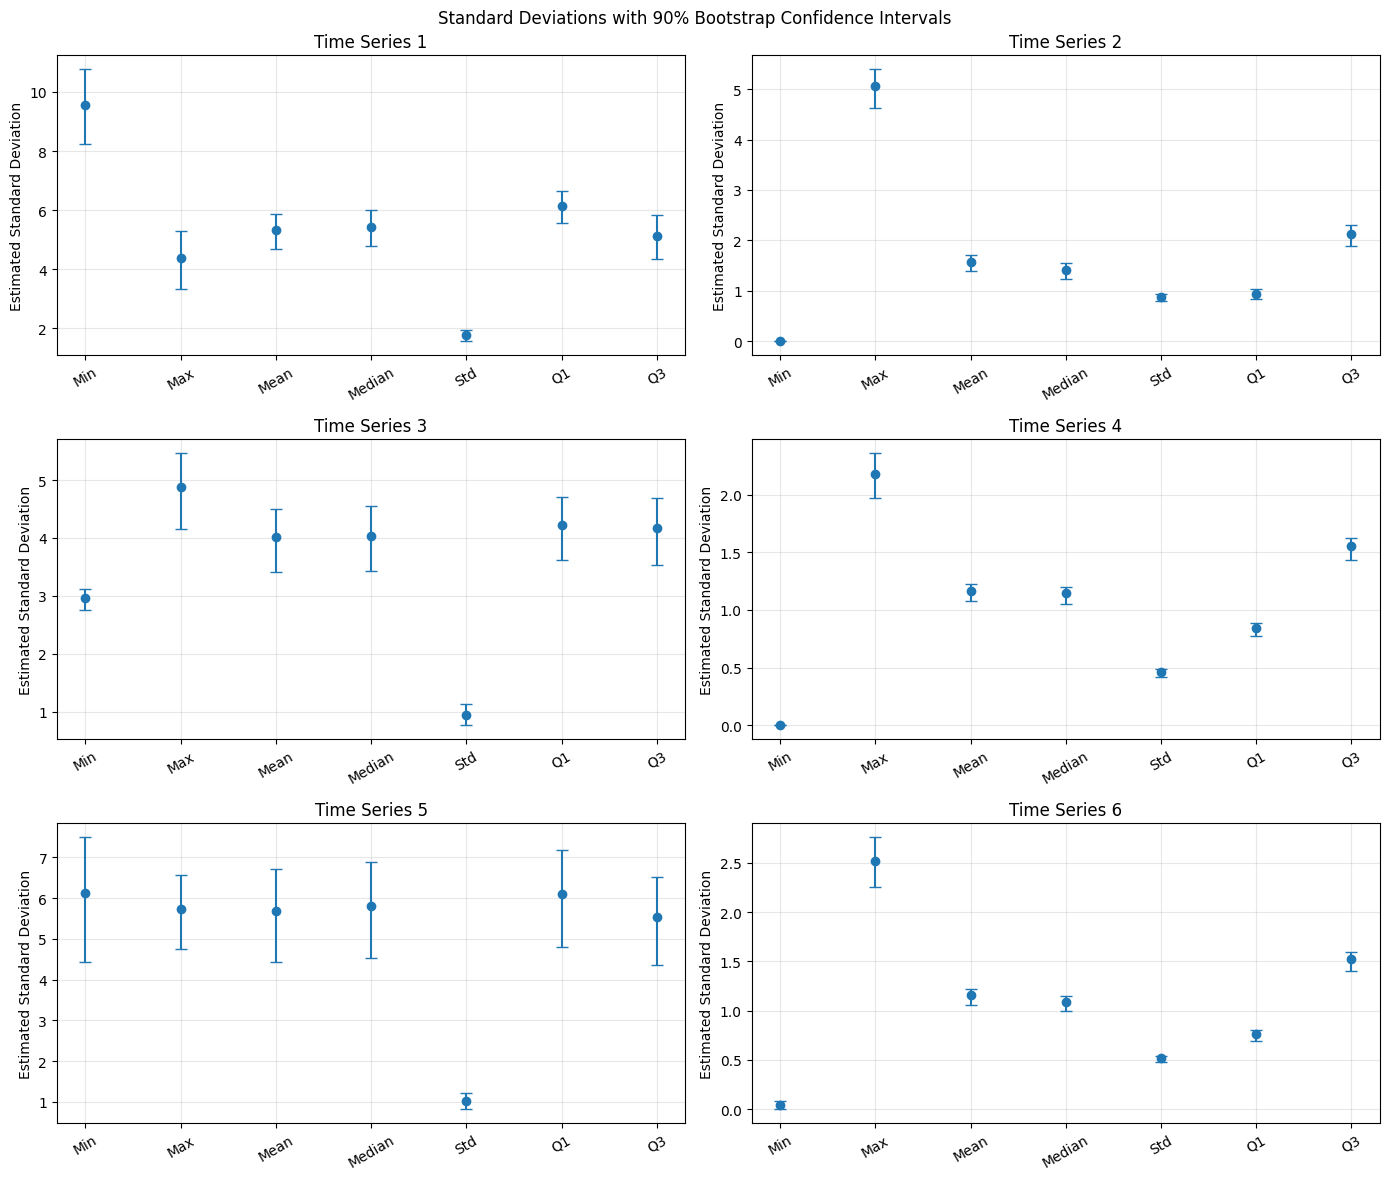

In [23]:
feature_labels = [
    "Min", "Max", "Mean", "Median",
    "Std", "Q1", "Q3"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, ax in enumerate(axes):
    result = std_summary.iloc[i * 7:(i + 1) * 7]

    estimates = result["Standard Deviation"].to_numpy()
    lower = result["90% CI Lower"].to_numpy()
    upper = result["90% CI Upper"].to_numpy()

    errors = np.vstack([
        estimates - lower,
        upper - estimates
    ])

    ax.errorbar(
        feature_labels,
        estimates,
        yerr=errors,
        fmt="o",
        capsize=4
    )

    ax.set_title(f"Time Series {i + 1}")
    ax.set_ylabel("Estimated Standard Deviation")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3)

plt.suptitle("Standard Deviations with 90% Bootstrap Confidence Intervals")
plt.tight_layout()
plt.show()

I selected the **maximum**, **mean**, and **third quartile** as the three most important features. The maximum captures peak activity, the mean represents the overall signal level, and the third quartile describes the upper range of the data while being less affected by extreme values. These features also show relatively large variations across the instances in the figure above.

## 2. ISLR 3.7.4

### (a) Linear Train

The cubic model should have a training RSS that is less than or equal to that of the linear model. Since the cubic model includes the extra terms $X^2$ and $X^3$, it has more flexibility to fit the training observations.

### (b) Linear Test

The linear model is expected to have a lower test RSS. Since the true relationship is linear, the terms $X^2$ and $X^3$ do not represent real patterns in the data. They may instead fit random noise in the training set, reducing the cubic model’s performance on new observations.

### (c) Not Linear Train

The cubic model should produce a training RSS that is no greater than that of the linear model. It has two additional terms, $X^2$ and $X^3$, which give it more freedom to follow the training observations.

### (d) Not Linear Testing

The test RSS cannot be determined from the given information. When the true pattern has substantial curvature, the cubic model may predict better. When the departure from linearity is small, the additional flexibility may mainly capture random noise, so the simpler linear model may achieve a lower test RSS.